# ML - Cenário Etanol

In [1]:
import pandas as pd
import numpy as np

import plotly.graph_objs as go
import matplotlib.pyplot as plt
import warnings
from statsmodels.tsa.arima.model import ARIMA
import plotly.express as px
import math

In [2]:
%matplotlib inline
warnings.filterwarnings("ignore")

In [3]:
#apontando para o caminho
Diretorio = r'DataSetTratado\tbl_combustivel_media_venda.csv'

In [4]:
#Lendo o arquivo
df = pd.DataFrame()
df = pd.read_csv(Diretorio, sep=";")

In [5]:
df_media_consumo_ano_etanol = df[(df.Produto=='ETANOL')]

In [6]:
df_media_consumo_ano_etanol['Ano'] = df_media_consumo_ano_etanol['Ano'].astype(str)
df_media_consumo_ano_etanol['Valor'] = round(df_media_consumo_ano_etanol['Valor'],2).astype(float)

In [7]:
df_media_consumo_ano_etanol

,Produto,Ano,Valor
0,ETANOL,2004,1.28
1,ETANOL,2005,1.48
2,ETANOL,2006,1.78
3,ETANOL,2007,1.57
4,ETANOL,2008,1.58
5,ETANOL,2009,1.61
6,ETANOL,2010,1.79
7,ETANOL,2011,2.10
8,ETANOL,2012,2.10
9,ETANOL,2013,2.14


# 4 - Ridge Regression

In [8]:
#df_media_consumo_ano_etanol.rename(columns= {'Valor Medio de Venda': 'Valor'}, inplace=True)
df_media_consumo_ano_etanol = df_media_consumo_ano_etanol.drop(columns='Produto')

In [9]:
df_media_consumo_ano_etanol

,Ano,Valor
0,2004,1.28
1,2005,1.48
2,2006,1.78
3,2007,1.57
4,2008,1.58
5,2009,1.61
6,2010,1.79
7,2011,2.10
8,2012,2.10
9,2013,2.14


In [10]:
#cenário Etanol
from sklearn.preprocessing import MinMaxScaler
sc = MinMaxScaler(feature_range = (1.28, 6))
mc_df_scaled = sc.fit_transform(df_media_consumo_ano_etanol.drop(columns = ['Ano']))

In [11]:
mc_df_scaled

array([[1.28      ],
       [1.56868502],
       [2.00171254],
       [1.69859327],
       [1.71302752],
       [1.75633028],
       [2.01614679],
       [2.46360856],
       [2.46360856],
       [2.52134557],
       [2.68012232],
       [2.91107034],
       [3.56061162],
       [3.61834862],
       [3.95033639],
       [4.00807339],
       [4.05137615],
       [6.        ]])

In [12]:
mc_df_scaled.shape

(18, 1)

In [13]:
X = mc_df_scaled[:,:7]
y = mc_df_scaled[:,:7]

In [14]:
X

array([[1.28      ],
       [1.56868502],
       [2.00171254],
       [1.69859327],
       [1.71302752],
       [1.75633028],
       [2.01614679],
       [2.46360856],
       [2.46360856],
       [2.52134557],
       [2.68012232],
       [2.91107034],
       [3.56061162],
       [3.61834862],
       [3.95033639],
       [4.00807339],
       [4.05137615],
       [6.        ]])

In [15]:
X.shape

(18, 1)

In [16]:
X[0:1]

array([[1.28]])

In [17]:
y

array([[1.28      ],
       [1.56868502],
       [2.00171254],
       [1.69859327],
       [1.71302752],
       [1.75633028],
       [2.01614679],
       [2.46360856],
       [2.46360856],
       [2.52134557],
       [2.68012232],
       [2.91107034],
       [3.56061162],
       [3.61834862],
       [3.95033639],
       [4.00807339],
       [4.05137615],
       [6.        ]])

In [18]:
X = np.asarray(X)
y = np.asarray(y)
X.shape, y.shape

((18, 1), (18, 1))

In [19]:
X

array([[1.28      ],
       [1.56868502],
       [2.00171254],
       [1.69859327],
       [1.71302752],
       [1.75633028],
       [2.01614679],
       [2.46360856],
       [2.46360856],
       [2.52134557],
       [2.68012232],
       [2.91107034],
       [3.56061162],
       [3.61834862],
       [3.95033639],
       [4.00807339],
       [4.05137615],
       [6.        ]])

In [20]:
y

array([[1.28      ],
       [1.56868502],
       [2.00171254],
       [1.69859327],
       [1.71302752],
       [1.75633028],
       [2.01614679],
       [2.46360856],
       [2.46360856],
       [2.52134557],
       [2.68012232],
       [2.91107034],
       [3.56061162],
       [3.61834862],
       [3.95033639],
       [4.00807339],
       [4.05137615],
       [6.        ]])

In [21]:
split = int(0.70 * len(X))
X_treino = X[:split]
y_treino = y[:split]
X_teste = X[split:]
y_teste = y[split:]

In [22]:
X_treino.shape, y_treino.shape

((12, 1), (12, 1))

In [23]:
X_teste.shape, y_teste.shape

((6, 1), (6, 1))

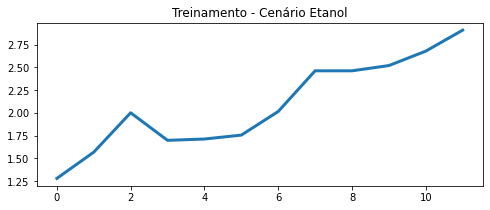

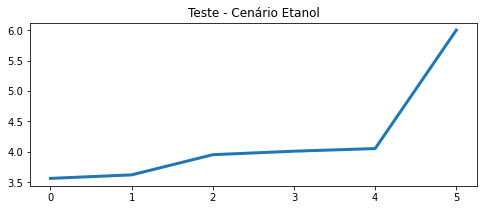

In [24]:
def show_plot_mc(data, title):
  plt.figure(figsize = (8, 3))
  plt.plot(data, linewidth = 3)
  plt.title(title)
  

show_plot_mc(X_treino, 'Treinamento - Cenário Etanol')
show_plot_mc(X_teste, 'Teste - Cenário Etanol')

In [25]:
from sklearn.linear_model import Ridge
regression_model = Ridge (alpha=0.1)
regression_model.fit(X_treino, y_treino)

Ridge(alpha=0.1)

In [26]:
lr_accuracy = regression_model.score(X_teste, y_teste)
print("Linear Regression Score: ", lr_accuracy)

Linear Regression Score:  0.9913034283591959


In [27]:
predicted_prices_mc = regression_model.predict(X)
predicted_prices_mc

array([[1.30757801],
       [1.58642837],
       [2.00470391],
       [1.71191104],
       [1.72585355],
       [1.76768111],
       [2.01864643],
       [2.45086449],
       [2.45086449],
       [2.50663456],
       [2.66000226],
       [2.88308255],
       [3.51049585],
       [3.56626593],
       [3.88694384],
       [3.94271391],
       [3.98454147],
       [5.86678139]])

In [28]:
len(predicted_prices_mc)

18

In [29]:
predicted_mc = []
for i in predicted_prices_mc:
  predicted_mc.append(i[0])

In [30]:
mc_fechamento = []
for i in mc_df_scaled:
  mc_fechamento.append(i[0])

In [31]:
mc_predicao = pd.DataFrame(columns = ['Ano' , 'ValorReal', 'ValorPreditivo'])
mc_predicao['Ano'] = df_media_consumo_ano_etanol['Ano']
mc_predicao['ValorReal'] = mc_fechamento
mc_predicao['ValorPreditivo'] = predicted_mc
mc_predicao

,Ano,ValorReal,ValorPreditivo
0,2004,1.280000,1.307578
1,2005,1.568685,1.586428
2,2006,2.001713,2.004704
3,2007,1.698593,1.711911
4,2008,1.713028,1.725854
5,2009,1.756330,1.767681
6,2010,2.016147,2.018646
7,2011,2.463609,2.450864
8,2012,2.463609,2.450864
9,2013,2.521346,2.506635


In [32]:
def interactive_plot(Ano, title):
  fig = px.line(title = title)
  
  fig.update_layout(legend=dict(
    yanchor="top", y=0.99, xanchor="left", x=0.01))

  for i in Ano.columns[1:]:
    fig.add_scatter(x = Ano['Ano'], y = Ano[i], name = i)
  fig.show()



In [33]:
interactive_plot(mc_predicao, "Cenário Etanol (Ridge Regression) - Preditivo")

In [34]:
import sklearn.metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Cálculo do erro
mse = mean_squared_error(mc_predicao['ValorReal'], mc_predicao['ValorPreditivo'])
print('MSE: '+str(mse))
mae = mean_absolute_error(mc_predicao['ValorReal'], mc_predicao['ValorPreditivo'])
print('MAE: '+str(mae))
rmse = math.sqrt(mean_squared_error(mc_predicao['ValorReal'], mc_predicao['ValorPreditivo']))
print('RMSE: '+str(rmse))

MSE: 0.0021677443661257175
MAE: 0.03375654521233857
RMSE: 0.0465590417225883


# 5 - RNN - LSTM

In [35]:
training_data = df_media_consumo_ano_etanol.iloc[:, 1:].values
training_data 

array([[1.28],
       [1.48],
       [1.78],
       [1.57],
       [1.58],
       [1.61],
       [1.79],
       [2.1 ],
       [2.1 ],
       [2.14],
       [2.25],
       [2.41],
       [2.86],
       [2.9 ],
       [3.13],
       [3.17],
       [3.2 ],
       [4.55]])

In [36]:
len(training_data) 

18

In [37]:
sc = MinMaxScaler(feature_range = (1.28, 6))
training_set_scaled = sc.fit_transform(training_data)

In [38]:
training_set_scaled

array([[1.28      ],
       [1.56868502],
       [2.00171254],
       [1.69859327],
       [1.71302752],
       [1.75633028],
       [2.01614679],
       [2.46360856],
       [2.46360856],
       [2.52134557],
       [2.68012232],
       [2.91107034],
       [3.56061162],
       [3.61834862],
       [3.95033639],
       [4.00807339],
       [4.05137615],
       [6.        ]])

In [39]:
X = []
y = []
for i in range(1, len(df_media_consumo_ano_etanol)):
    X.append(training_set_scaled [i-1:i, 0]) 
    y.append(training_set_scaled [i, 0])

In [40]:
X

[array([1.28]),
 array([1.56868502]),
 array([2.00171254]),
 array([1.69859327]),
 array([1.71302752]),
 array([1.75633028]),
 array([2.01614679]),
 array([2.46360856]),
 array([2.46360856]),
 array([2.52134557]),
 array([2.68012232]),
 array([2.91107034]),
 array([3.56061162]),
 array([3.61834862]),
 array([3.95033639]),
 array([4.00807339]),
 array([4.05137615])]

In [41]:
y

[1.5686850152905198,
 2.0017125382263,
 1.6985932721712538,
 1.7130275229357799,
 1.7563302752293581,
 2.016146788990826,
 2.4636085626911317,
 2.4636085626911317,
 2.5213455657492356,
 2.6801223241590217,
 2.911070336391438,
 3.560611620795107,
 3.6183486238532114,
 3.950336391437309,
 4.008073394495414,
 4.051376146788991,
 6.0]

In [42]:
X = np.asarray(X)
y = np.asarray(y)

In [43]:
X.shape , y.shape

((17, 1), (17,))

In [44]:
split = int(0.7 * len(X))
X_train = X[:split]
y_train = y[:split]
X_test = X[split:]
y_test = y[split:]

In [45]:
X_train.shape , y_train.shape, X_test.shape, y_test.shape

((11, 1), (11,), (6, 1), (6,))

In [46]:
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))
X_train.shape, X_test.shape

((11, 1, 1), (6, 1, 1))

In [47]:
X_train

array([[[1.28      ]],

       [[1.56868502]],

       [[2.00171254]],

       [[1.69859327]],

       [[1.71302752]],

       [[1.75633028]],

       [[2.01614679]],

       [[2.46360856]],

       [[2.46360856]],

       [[2.52134557]],

       [[2.68012232]]])

In [48]:
X_train.shape

(11, 1, 1)

In [49]:
from tensorflow import keras

In [50]:
inputs = keras.layers.Input(shape=(X_train.shape[1], X_train.shape[2]))
x = keras.layers.LSTM(245, return_sequences= True)(inputs)
x = keras.layers.Dropout(0.1)(x) 
x = keras.layers.LSTM(245, return_sequences=True)(x)
x = keras.layers.Dropout(0.1)(x)
x = keras.layers.LSTM(245)(x)
outputs = keras.layers.Dense(1, activation='linear')(x)

model = keras.Model(inputs=inputs, outputs=outputs)
model.compile(optimizer='adam', loss="mse")
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 1, 1)]            0         
                                                                 
 lstm (LSTM)                 (None, 1, 245)            242060    
                                                                 
 dropout (Dropout)           (None, 1, 245)            0         
                                                                 
 lstm_1 (LSTM)               (None, 1, 245)            481180    
                                                                 
 dropout_1 (Dropout)         (None, 1, 245)            0         
                                                                 
 lstm_2 (LSTM)               (None, 245)               481180    
                                                                 
 dense (Dense)               (None, 1)                 246   

In [51]:
X_train.shape, y_train.shape

((11, 1, 1), (11,))

In [52]:
history = model.fit(
    X_train, y_train,
    epochs = 20,
    batch_size = 32,
    validation_split = 0.2
)

Epoch 1/20
1/1 [==============================] - 17s 17s/step - loss: 3.9530 - val_loss: 7.2661
Epoch 2/20
1/1 [==============================] - 0s 119ms/step - loss: 3.9021 - val_loss: 7.1796
Epoch 3/20
1/1 [==============================] - 0s 110ms/step - loss: 3.8500 - val_loss: 7.0804
Epoch 4/20
1/1 [==============================] - 0s 112ms/step - loss: 3.7892 - val_loss: 6.9618
Epoch 5/20
1/1 [==============================] - 0s 79ms/step - loss: 3.7192 - val_loss: 6.8188
Epoch 6/20
1/1 [==============================] - 0s 129ms/step - loss: 3.6338 - val_loss: 6.6469
Epoch 7/20
1/1 [==============================] - 0s 198ms/step - loss: 3.5339 - val_loss: 6.4418
Epoch 8/20
1/1 [==============================] - 0s 99ms/step - loss: 3.4193 - val_loss: 6.1988
Epoch 9/20
1/1 [==============================] - 0s 117ms/step - loss: 3.2743 - val_loss: 5.9133
Epoch 10/20
1/1 [==============================] - 0s 99ms/step - loss: 3.1169 - val_loss: 5.5808
Epoch 11/20
1/1 [======

In [53]:
predicted_LSTM = model.predict(X)

1/1 [==============================] - 3s 3s/step


In [54]:
predicted_LSTM

array([[1.2873411],
       [1.5037011],
       [1.8441375],
       [1.603915 ],
       [1.615155 ],
       [1.648997 ],
       [1.8557881],
       [2.2254744],
       [2.2254744],
       [2.274275 ],
       [2.409607 ],
       [2.6091104],
       [3.1824436],
       [3.233975 ],
       [3.531019 ],
       [3.5827293],
       [3.6215084]], dtype=float32)

In [55]:
predicted_LSTM.shape

(17, 1)

In [56]:
test_predicted_LSTM = []

for i in predicted_LSTM:
  test_predicted_LSTM.append(i[0]) 

In [57]:
len(test_predicted_LSTM)

17

In [58]:
df_predicao_LSTM = pd.DataFrame(columns = ['Ano' , 'ValorReal', 'ValorPreditivo'])

In [59]:
df_predicao_LSTM['Ano'] = df_media_consumo_ano_etanol[:-1]['Ano']

In [60]:
Fechamento_Scaled = []
for i in training_set_scaled:
  Fechamento_Scaled.append(i[0])

In [61]:
len(Fechamento_Scaled)

18

In [62]:
df_predicao_LSTM['ValorReal'] = Fechamento_Scaled[:-1]

In [63]:
df_predicao_LSTM['ValorPreditivo'] = test_predicted_LSTM

In [64]:
interactive_plot(df_predicao_LSTM, "Cenário Etanol - LSTM")

In [65]:
#Cálculo do erro
mse = mean_squared_error(df_predicao_LSTM['ValorReal'], df_predicao_LSTM['ValorPreditivo'])
print('MSE: '+str(mse))
mae = mean_absolute_error(df_predicao_LSTM['ValorReal'], df_predicao_LSTM['ValorPreditivo'])
print('MAE: '+str(mae))
rmse = math.sqrt(mean_squared_error(df_predicao_LSTM['ValorReal'], df_predicao_LSTM['ValorPreditivo']))
print('RMSE: '+str(rmse))

MSE: 0.07388166053395695
MAE: 0.23664871223368755
RMSE: 0.27181181088016937
